# Week 7 - Day 1

# Convolutional Neural Networks (CNN): Convolution & Pooling

## A Beginner-Friendly, Fully Explained Walkthrough

In Week 6, every image we used was turned into a flat list of numbers (`Flatten()`) before it went anywhere near a `Dense` layer. That worked well, but it threw away something important: **where each pixel sits next to its neighbours.**

Today we slow right down and build up, piece by piece, a new kind of network - the **Convolutional Neural Network (CNN)** - that is specifically designed to keep that spatial information. We will not rush. Every single code cell in this notebook is followed by a plain-English, line-by-line explanation of what just happened and why we did it that way.

By the end, we will have built a real, working CNN using Keras, and compared it side-by-side with Week 6 Day 2's ANN.

## Learning Objectives

By the end of this lesson, you will be able to:

- Explain, in your own words, why flattening an image early loses useful information.
- Explain what a filter (kernel) is, and how it slides across an image.
- Read and explain every line of a hand-written NumPy convolution function.
- Use Sobel filters to detect edges in an image, and explain that this is just convolution with hand-chosen numbers.
- Explain padding and stride, and predict how each changes the size of a convolution's output.
- Explain what pooling does, and the difference between max pooling and average pooling.
- Describe the overall shape of a CNN: Conv → ReLU → Pool → ... → Flatten → Dense.
- Read every line of a real Keras CNN (`Conv2D`, `MaxPooling2D`) and explain what each layer is doing.
- Train and evaluate a CNN, and compare it fairly against an ANN on the same data.

## Why This Lesson Matters

Imagine you are looking at a photo of a Nigerian passport to check if it's genuine. What tells you it's real isn't just "this pixel is dark, that pixel is light" - it's the **pattern**: a straight edge here, a curved letter there, a photo in a specific corner. The *arrangement* of pixels matters just as much as the pixels themselves.

When we flattened an image in Week 6, we turned a neat grid into one long line of numbers. A pixel's neighbour directly above it and a pixel three rows away both just became "some other number further along the list" - the network lost all sense of "this pixel is right next to that one." A CNN is built specifically to never lose that sense of position, for as long as possible.

## Recap: Week 6 -> Week 7

| | ANN (Week 6) | CNN (Week 7 - today) |
|---|---|---|
| First step on an image | `Flatten()` immediately - turns the grid into one long line | Keeps the image as a 2-D grid for as long as possible |
| What it looks for | Patterns across all 64 numbers at once, with no sense of "neighbour" | Local patterns (edges, curves) using a small filter that slides around |
| Parameters needed | Grows quickly as images get bigger | The same small filter is reused everywhere - far fewer numbers to learn |
| Best suited for | Spreadsheet-style data; very small/simple images | Images in general - photos, scans, X-rays, and more |

Everything you already know still applies here: neurons, weights, activation functions, epochs, loss, and the Sequential API from Week 6 are all still exactly the same. Today we are adding **two new kinds of layers** - `Conv2D` and `MaxPooling2D` - that go *before* the `Flatten()` step you already know.

# Part 1 - What Flattening Actually Throws Away

Before we learn the fix, let's really *see* the problem. We'll take one digit image, look at it normally, and then look at what it becomes after `Flatten()`.

Original image shape: (8, 8)
Flattened shape: (64,)


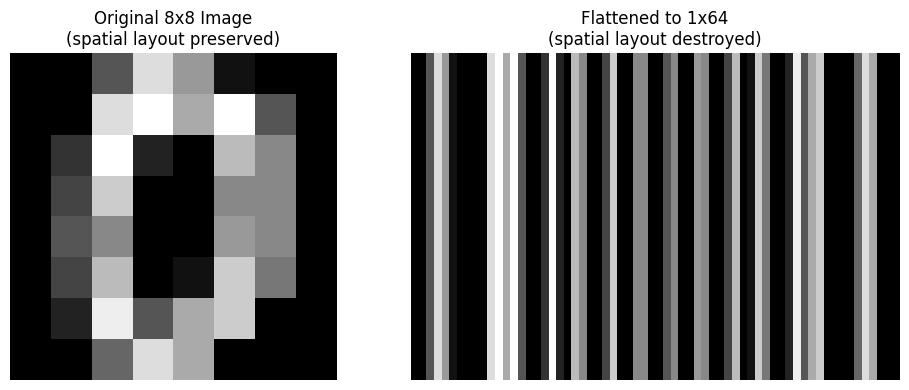

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

digits = load_digits()

sample_image = digits.images[0]
print("Original image shape:", sample_image.shape)

flattened = sample_image.flatten()
print("Flattened shape:", flattened.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(sample_image, cmap="gray")
axes[0].set_title("Original 8x8 Image\n(spatial layout preserved)")
axes[0].axis("off")

axes[1].imshow(flattened.reshape(1, -1), cmap="gray", aspect="auto")
axes[1].set_title("Flattened to 1x64\n(spatial layout destroyed)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

### Let's Walk Through This Code, Line by Line

We are going to do this for every code cell in this notebook - it might feel slow at first, but it means you will never be stuck wondering "wait, what did that line actually do?"

- **`import numpy as np`** - NumPy is the library that gives Python fast, powerful support for grids of numbers (called *arrays*). Almost every calculation in this notebook secretly uses NumPy underneath.
- **`import pandas as pd`** - Pandas is our tool for working with tables of data (rows and columns), the same library from every earlier week.
- **`import matplotlib.pyplot as plt`** - Matplotlib is how we draw charts and images. `plt` is just a short nickname so we don't have to type "matplotlib.pyplot" every time.
- **`from sklearn.datasets import load_digits`** - This imports one function, `load_digits`, from scikit-learn's built-in collection of "toy" (small, ready-to-use) datasets.
- **`digits = load_digits()`** - This actually runs that function and stores everything it returns (images, labels, and more) inside a variable called `digits`.
- **`sample_image = digits.images[0]`** - `digits.images` is a big stack of every image in the dataset, already shaped as proper 8-row-by-8-column grids. `[0]` means "give me the very first one." We store it as `sample_image`.
- **`print("Original image shape:", sample_image.shape)`** - `.shape` tells us the dimensions of an array. For an 8x8 image, this prints `(8, 8)` - 8 rows, 8 columns.
- **`flattened = sample_image.flatten()`** - `.flatten()` takes any grid and squashes it into one long, single-row list of numbers, reading left-to-right, top-to-bottom. An 8x8 grid (64 numbers total) becomes one row of 64 numbers.
- **`print("Flattened shape:", flattened.shape)`** - This will print `(64,)`, confirming it's now a single flat line of 64 numbers instead of an 8x8 grid.
- **`fig, axes = plt.subplots(1, 2, figsize=(10, 4))`** - This sets up a drawing canvas (`fig`) split into 1 row and 2 side-by-side plot areas (`axes`), sized 10 inches wide by 4 inches tall. (We covered exactly what `axes` means back in Week 6 - it's your handle for controlling each individual mini-plot.)
- **`axes[0].imshow(sample_image, cmap="gray")`** - `imshow` displays an array as an image. `axes[0]` means "draw this in the *first* subplot." `cmap="gray"` tells matplotlib to use black-to-white shading (since these are grayscale digit images, not colour photos).
- **`axes[0].set_title(...)` and `axes[0].axis("off")`** - Adds a caption above the image, and hides the x/y axis number labels and border lines, since they'd just be visual clutter here.
- **The same three lines are repeated for `axes[1]`**, but showing the *flattened* version instead, reshaped to `(1, -1)` (1 row, and "however many columns are needed" - the `-1` tells NumPy to work that number out automatically) purely so `imshow` has something 2-D to draw.
- **`plt.tight_layout()`** - Automatically adjusts spacing so titles and images don't overlap or get cut off.
- **`plt.show()`** - Actually renders and displays everything we've built.

### Observation

The right-hand image contains the **exact same 64 numbers** as the left. But look how differently they read visually - the neat digit shape on the left has become a meaningless stripe of pixels on the right. A `Dense` layer looking only at the flattened version has no built-in way of knowing that a particular pixel was directly *below* another one in the original grid. That "who is my neighbour" information is exactly what a CNN is built to preserve.

# Part 2 - The Convolution Operation

**Convolution** is the core trick that makes a CNN a CNN. Here's the plain-language version before we touch any code:

> Imagine sliding a small transparent square (say, 3 pixels by 3 pixels) across a bigger image, one step at a time. At every single position, you multiply the 9 numbers under that square by 9 "importance" numbers (the filter), add them all up, and write down that one total. Once you've slid the square across the *entire* image, you're left with a brand-new, smaller grid of totals. That new grid is called a **feature map**.

The filter's 9 numbers are chosen (or, in a real CNN, *learned*) so that the total comes out **large** wherever the pattern the filter is "looking for" appears, and **small** everywhere else.

<svg viewBox="0 0 900 420" xmlns="http://www.w3.org/2000/svg">
  <rect width="900" height="420" fill="#f8f9fa"/>
  <text x="450" y="35" font-size="18" font-weight="bold" text-anchor="middle" fill="#1565c0">Sliding a 3x3 Filter Across an Image</text>

  <text x="150" y="70" font-size="13" font-weight="bold" text-anchor="middle" fill="#333">Input Image (grid of pixels)</text>
  <g transform="translate(30,90)">
    <rect width="240" height="240" fill="none" stroke="#333" stroke-width="1"/>
    <line x1="60" y1="0" x2="60" y2="240" stroke="#ccc"/>
    <line x1="120" y1="0" x2="120" y2="240" stroke="#ccc"/>
    <line x1="180" y1="0" x2="180" y2="240" stroke="#ccc"/>
    <line x1="0" y1="60" x2="240" y2="60" stroke="#ccc"/>
    <line x1="0" y1="120" x2="240" y2="120" stroke="#ccc"/>
    <line x1="0" y1="180" x2="240" y2="180" stroke="#ccc"/>
    <rect x="60" y="60" width="180" height="180" fill="none" stroke="#ccc"/>
    <rect x="0" y="0" width="180" height="180" fill="#bbdefb" fill-opacity="0.5" stroke="#1565c0" stroke-width="3"/>
    <text x="90" y="95" font-size="12" text-anchor="middle" fill="#0d47a1">3x3 filter</text>
    <text x="90" y="112" font-size="12" text-anchor="middle" fill="#0d47a1">window</text>
  </g>

  <text x="450" y="200" font-size="30" text-anchor="middle" fill="#455a64">→</text>
  <text x="450" y="225" font-size="12" text-anchor="middle" fill="#666">multiply, then add</text>
  <text x="450" y="240" font-size="12" text-anchor="middle" fill="#666">everything up</text>

  <text x="680" y="70" font-size="13" font-weight="bold" text-anchor="middle" fill="#333">Output Feature Map</text>
  <g transform="translate(580,90)">
    <rect width="200" height="200" fill="none" stroke="#333" stroke-width="1"/>
    <line x1="40" y1="0" x2="40" y2="200" stroke="#ccc"/>
    <line x1="80" y1="0" x2="80" y2="200" stroke="#ccc"/>
    <line x1="120" y1="0" x2="120" y2="200" stroke="#ccc"/>
    <line x1="160" y1="0" x2="160" y2="200" stroke="#ccc"/>
    <line x1="0" y1="40" x2="200" y2="40" stroke="#ccc"/>
    <line x1="0" y1="80" x2="200" y2="80" stroke="#ccc"/>
    <line x1="0" y1="120" x2="200" y2="120" stroke="#ccc"/>
    <line x1="0" y1="160" x2="200" y2="160" stroke="#ccc"/>
    <rect x="0" y="0" width="40" height="40" fill="#c8e6c9" stroke="#2e7d32" stroke-width="2"/>
    <text x="20" y="25" font-size="12" text-anchor="middle" fill="#2e7d32">Σ</text>
  </g>

  <rect x="150" y="340" width="600" height="60" rx="10" fill="#eceff1" stroke="#455a64" stroke-width="2"/>
  <text x="450" y="365" font-size="12" text-anchor="middle" fill="#333">The filter slides one step at a time (left to right, top to bottom).</text>
  <text x="450" y="385" font-size="12" text-anchor="middle" fill="#333">Each position produces ONE number in the output feature map.</text>
</svg>

### An Everyday Analogy

Think of a security guard checking market stalls one by one for a specific item - say, counterfeit naira notes with a particular missing watermark pattern. The guard doesn't look at the whole market at once; they check *one stall at a time*, using the *same* checklist (the filter) at every stall, and note down "suspicious" or "fine" for each one. By the end, they have a full map of the market showing exactly which stalls raised suspicion. That "map of suspicion levels" is the feature map.

### Now Let's Build This Ourselves

We'll write a function that does exactly what the diagram shows, one small piece at a time.

In [2]:
def convolve2d(image, kernel):
    """A simple, unoptimized 2D convolution (no padding, stride = 1)."""
    image_h, image_w = image.shape
    kernel_h, kernel_w = kernel.shape

    output_h = image_h - kernel_h + 1
    output_w = image_w - kernel_w + 1
    output = np.zeros((output_h, output_w))

    for i in range(output_h):
        for j in range(output_w):
            patch = image[i:i + kernel_h, j:j + kernel_w]
            output[i, j] = np.sum(patch * kernel)

    return output

### Line-by-Line Breakdown

- **`def convolve2d(image, kernel):`** - We're defining our own function, called `convolve2d`, that takes two inputs: `image` (the big grid) and `kernel` (the small filter grid). "def" is short for "define."
- **`image_h, image_w = image.shape`** - `.shape` gives us `(rows, columns)`. We immediately split that into two separate variables: `image_h` (height) and `image_w` (width), so we can use them by name instead of remembering index positions.
- **`kernel_h, kernel_w = kernel.shape`** - Same idea, but for the filter's own height and width.
- **`output_h = image_h - kernel_h + 1`** and **`output_w = image_w - kernel_w + 1`** - This calculates how many valid positions the filter can slide into. Think of a 3-wide filter sliding along a 5-wide row: it can start at position 0, 1, or 2 (three positions) before it would hang off the edge - and `5 - 3 + 1 = 3` confirms that.
- **`output = np.zeros((output_h, output_w))`** - We create an empty grid, filled with zeros, of exactly the right output size. We'll fill in the real numbers as we calculate them.
- **`for i in range(output_h):`** and **`for j in range(output_w):`** - Two nested loops: the outer loop walks down each *row* position (`i`), and the inner loop walks across each *column* position (`j`) - together, `i` and `j` visit every valid sliding position, top-to-bottom, left-to-right.
- **`patch = image[i:i + kernel_h, j:j + kernel_w]`** - This is "slicing": it grabs the small chunk of the image directly under the filter's current position - starting at row `i` for `kernel_h` rows, and starting at column `j` for `kernel_w` columns.
- **`output[i, j] = np.sum(patch * kernel)`** - `patch * kernel` multiplies the two grids *element by element* (top-left of patch with top-left of kernel, and so on) - NOT regular matrix multiplication. `np.sum(...)` then adds every one of those multiplied values into a single number, which we store at position `[i, j]` in our output grid.
- **`return output`** - Once both loops finish (every position has been checked), we hand back the completed feature map.

In [3]:
# A tiny 5x5 "image" with a bright vertical stripe down the middle
tiny_image = np.array([
    [0, 0, 10, 0, 0],
    [0, 0, 10, 0, 0],
    [0, 0, 10, 0, 0],
    [0, 0, 10, 0, 0],
    [0, 0, 10, 0, 0],
], dtype=float)

# A simple vertical-edge-detecting filter
vertical_edge_filter = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1],
], dtype=float)

feature_map = convolve2d(tiny_image, vertical_edge_filter)
print("Input image:\n", tiny_image)
print("\nFeature map (output):\n", feature_map)

Input image:
 [[ 0.  0. 10.  0.  0.]
 [ 0.  0. 10.  0.  0.]
 [ 0.  0. 10.  0.  0.]
 [ 0.  0. 10.  0.  0.]
 [ 0.  0. 10.  0.  0.]]

Feature map (output):
 [[-30.   0.  30.]
 [-30.   0.  30.]
 [-30.   0.  30.]]


### Line-by-Line Breakdown

- **`tiny_image = np.array([...])`** - We hand-build a tiny 5x5 grid ourselves, using `np.array()` to turn a list-of-lists into a proper NumPy grid. The middle column is `10` (bright), and everything else is `0` (dark) - a simple vertical stripe, like a lit-up strip in the middle of a dark photo.
- **`dtype=float`** - Forces the numbers to be stored as decimals rather than whole numbers, which avoids rounding errors later.
- **`vertical_edge_filter = np.array([...])`** - Our hand-designed 3x3 filter: `1` on the left column, `0` in the middle, `-1` on the right column. This particular pattern reacts strongly wherever brightness changes from "bright on the left" to "dark on the right," or vice versa - exactly what happens at the two edges of our stripe.
- **`feature_map = convolve2d(tiny_image, vertical_edge_filter)`** - We call the function we just wrote, passing in our image and our filter, and store the result.
- **The two `print(...)` lines** just display the original image and the resulting feature map so we can compare them by eye.

### Reading the Result

Look closely at the feature map: it has **large (non-zero) values exactly where the stripe's edges are**, and values close to zero everywhere else - including right down the flat, unchanging middle of the stripe, and the flat, unchanging background. That's the entire point of a filter: it stays "quiet" over uniform regions and "shouts" wherever its target pattern shows up.

Also notice the feature map is **smaller** (`3x3`) than the original image (`5x5`) - a direct result of our `output_h = image_h - kernel_h + 1` formula. We'll fix that shrinking behaviour in Part 4, using something called padding.

# Part 3 - Real Edge Detection with Sobel Filters

Let's now apply this exact same idea to a real (synthetic) image, using the well-known **Sobel filters** mentioned in this week's lesson plan.

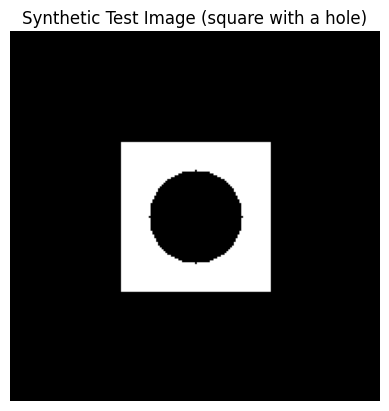

In [4]:
import cv2

# Build a simple synthetic image (a white square with a hole punched in it)
# so we always have a reliable image to work with, without needing internet access.
canvas = np.zeros((200, 200), dtype=np.uint8)
cv2.rectangle(canvas, (60, 60), (140, 140), color=255, thickness=-1)
cv2.circle(canvas, (100, 100), 25, color=0, thickness=-1)

plt.imshow(canvas, cmap="gray")
plt.title("Synthetic Test Image (square with a hole)")
plt.axis("off")
plt.show()

### Line-by-Line Breakdown

- **`import cv2`** - This imports OpenCV, a widely-used library for image processing and computer vision. (`cv2` is simply its Python package name.)
- **`canvas = np.zeros((200, 200), dtype=np.uint8)`** - Creates a 200x200 grid, entirely filled with zeros - a completely black square image to start with. `dtype=np.uint8` means each pixel is stored as a whole number from 0 to 255, the standard way image brightness is stored.
- **`cv2.rectangle(canvas, (60, 60), (140, 140), color=255, thickness=-1)`** - Draws directly onto `canvas`: a rectangle with its top-left corner at pixel `(60, 60)` and bottom-right corner at `(140, 140)`, filled in white (`color=255`). `thickness=-1` is OpenCV's way of saying "fill the whole shape in," rather than just drawing its outline.
- **`cv2.circle(canvas, (100, 100), 25, color=0, thickness=-1)`** - Draws a filled black circle centred at `(100, 100)` with a radius of `25` pixels, right on top of the white square - this "punches a hole" through the middle of it.
- **The final three lines** display the resulting image, exactly the same `imshow` / `title` / `axis` / `show` pattern we've now used several times.

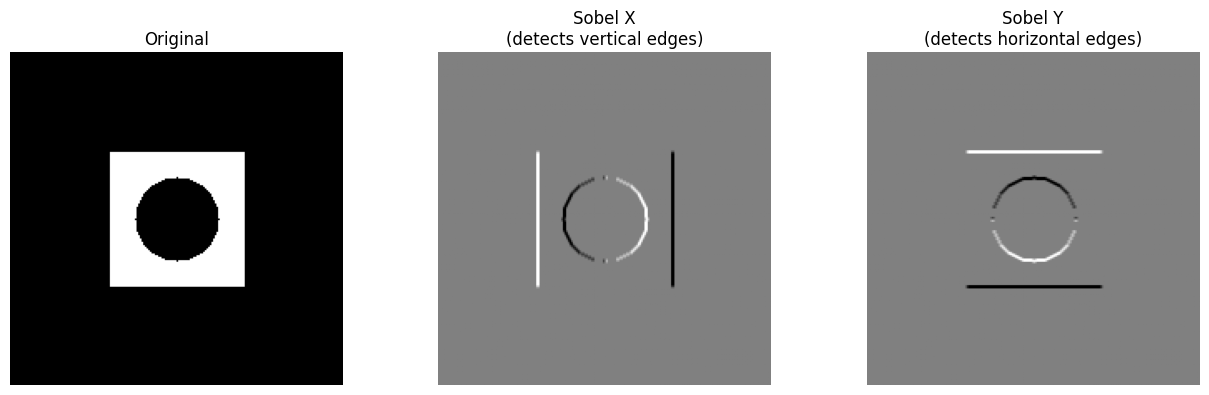

In [5]:
sobel_x = cv2.Sobel(canvas, cv2.CV_64F, dx=1, dy=0, ksize=3)
sobel_y = cv2.Sobel(canvas, cv2.CV_64F, dx=0, dy=1, ksize=3)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(canvas, cmap="gray")
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(sobel_x, cmap="gray")
axes[1].set_title("Sobel X\n(detects vertical edges)")
axes[1].axis("off")

axes[2].imshow(sobel_y, cmap="gray")
axes[2].set_title("Sobel Y\n(detects horizontal edges)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

### Line-by-Line Breakdown

- **`cv2.Sobel(canvas, cv2.CV_64F, dx=1, dy=0, ksize=3)`** - Runs a Sobel convolution on `canvas`. `cv2.CV_64F` tells OpenCV to store the result using high-precision decimal numbers (since edge strength can be negative, which a plain `uint8` image format can't represent). `dx=1, dy=0` means "detect changes in brightness as we move left-to-right" (i.e. vertical edges). `ksize=3` means the built-in Sobel filter is 3x3, the same size as our hand-made filter in Part 2.
- **`sobel_y = cv2.Sobel(canvas, cv2.CV_64F, dx=0, dy=1, ksize=3)`** - The same idea, but `dx=0, dy=1` instead detects changes as we move top-to-bottom (i.e. horizontal edges).
- **The rest of the cell** simply displays all three images side by side, using the same `subplots` pattern from Part 1.

### What Just Happened?

`cv2.Sobel` is doing **exactly** what our hand-written `convolve2d()` function did in Part 2 - sliding a small filter across the image and summing up the results - it's just a highly optimized, ready-made version, using filter numbers that mathematicians have already worked out are especially good at detecting edges.

**The key idea to remember for CNNs:** in Sobel filtering, a human chose the filter's numbers in advance. In a real CNN, the filter's numbers (just like the weights in the Perceptron from Week 6 Day 1) start off random, and the network **learns** the best values on its own from the training data - discovering whichever filters (edge detectors, corner detectors, curve detectors, and more) actually help it solve the task.

# Part 4 - Padding and Stride

We noticed in Part 2 that convolution **shrinks** the image. Two settings let us control that.

### Padding, in Plain Language

Imagine writing on a piece of paper, but you're worried about running out of room right at the very edge. **Padding** solves this by adding a border of zeros around the outside of the image *before* sliding the filter, so the filter has "room" to be centred even on what used to be an edge pixel.

- **`padding="valid"`** - no border added; the output shrinks, exactly like our hand-written function did.
- **`padding="same"`** - Keras automatically works out exactly how much zero-border to add so the output ends up the *same* width and height as the input.

### Stride, in Plain Language

**Stride** is simply "how many pixels does the filter jump each time it moves?"

- **`stride=1`** - move one pixel at a time (what our hand-written function did) - produces a bigger, more detailed feature map, but takes more calculations.
- **`stride=2`** - jump two pixels at a time - produces a smaller feature map, faster to compute, but with less fine detail.

In [6]:
def convolve2d_strided(image, kernel, stride=1):
    image_h, image_w = image.shape
    kernel_h, kernel_w = kernel.shape

    output_h = (image_h - kernel_h) // stride + 1
    output_w = (image_w - kernel_w) // stride + 1
    output = np.zeros((output_h, output_w))

    for i in range(output_h):
        for j in range(output_w):
            row = i * stride
            col = j * stride
            patch = image[row:row + kernel_h, col:col + kernel_w]
            output[i, j] = np.sum(patch * kernel)

    return output

### Line-by-Line Breakdown

This is almost identical to our Part 2 `convolve2d()` function - here's exactly what changed and why:

- **`def convolve2d_strided(image, kernel, stride=1):`** - We add a new input, `stride`, with a default value of `1` (so it behaves like our original function unless we say otherwise).
- **`output_h = (image_h - kernel_h) // stride + 1`** - The `//` symbol means "divide, then round down to a whole number" (integer division). Dividing by the stride is how we account for the filter skipping positions - a bigger stride means fewer valid stopping points, so a smaller output.
- **`row = i * stride`** and **`col = j * stride`** - Instead of moving one pixel per loop step (like before), we now jump `stride` pixels for every step of `i` or `j`. When `stride=1`, this behaves exactly as before (`row = i`). When `stride=2`, `row` skips 0, 2, 4, 6... instead of 0, 1, 2, 3...
- **Everything else** (grabbing the `patch`, multiplying by `kernel`, summing it) is unchanged from Part 2.

In [7]:
bigger_image = np.random.randint(0, 10, size=(8, 8)).astype(float)
simple_filter = np.ones((3, 3)) / 9  # a simple averaging filter

stride1_output = convolve2d_strided(bigger_image, simple_filter, stride=1)
stride2_output = convolve2d_strided(bigger_image, simple_filter, stride=2)

print("Input shape:", bigger_image.shape)
print("Output shape with stride=1:", stride1_output.shape)
print("Output shape with stride=2:", stride2_output.shape)

Input shape: (8, 8)
Output shape with stride=1: (6, 6)
Output shape with stride=2: (3, 3)


### Line-by-Line Breakdown

- **`np.random.randint(0, 10, size=(8, 8))`** - Generates an 8x8 grid of random whole numbers between 0 (inclusive) and 10 (exclusive). We use random numbers here purely to have *some* image to test with - the actual values don't matter for this demonstration.
- **`.astype(float)`** - Converts those whole numbers into decimals, matching what our function expects.
- **`simple_filter = np.ones((3, 3)) / 9`** - `np.ones((3, 3))` makes a 3x3 grid entirely filled with `1`s. Dividing the whole grid by `9` turns every value into `1/9`. This particular filter, when convolved, computes the *average* of the 9 pixels underneath it - useful for smoothing/blurring an image.
- **The rest of the cell** runs our strided function twice (once with `stride=1`, once with `stride=2`) and prints the resulting shapes so we can directly compare them.

### Observation

With the same 8x8 input and 3x3 filter, `stride=1` produces a `6x6` output, while `stride=2` produces only a `3x3` output. Larger strides mean less computation, but also a coarser (less detailed) feature map - a genuine trade-off you'll make when designing real CNNs.

# Part 5 - Pooling

After convolution, CNNs typically shrink the feature map further using a **pooling** layer, keeping only the most important information from each small region.

In [8]:
def max_pool2d(feature_map, pool_size=2, stride=2):
    h, w = feature_map.shape
    output_h = (h - pool_size) // stride + 1
    output_w = (w - pool_size) // stride + 1
    output = np.zeros((output_h, output_w))

    for i in range(output_h):
        for j in range(output_w):
            row = i * stride
            col = j * stride
            patch = feature_map[row:row + pool_size, col:col + pool_size]
            output[i, j] = np.max(patch)

    return output

def average_pool2d(feature_map, pool_size=2, stride=2):
    h, w = feature_map.shape
    output_h = (h - pool_size) // stride + 1
    output_w = (w - pool_size) // stride + 1
    output = np.zeros((output_h, output_w))

    for i in range(output_h):
        for j in range(output_w):
            row = i * stride
            col = j * stride
            patch = feature_map[row:row + pool_size, col:col + pool_size]
            output[i, j] = np.mean(patch)

    return output

### Line-by-Line Breakdown

Notice this looks *very* similar to our strided convolution function from Part 4 - pooling really is just "slide a small window and summarise what's inside it," the same sliding pattern, just with a different summary rule:

- **`max_pool2d(feature_map, pool_size=2, stride=2)`** - Same sliding-window setup as before (`pool_size` plays the same role `kernel` size did). The key difference is the very last line inside the loop: **`output[i, j] = np.max(patch)`** - instead of multiplying by filter numbers and summing, we simply take the single **largest** value found in that little window.
- **`average_pool2d(...)`** - Identical structure, except the last line is **`output[i, j] = np.mean(patch)`**, which takes the **average** of the values in that window instead of the maximum.

That's genuinely the entire difference between max pooling and average pooling: "pick the biggest value" versus "average all the values." 

In [9]:
sample_feature_map = np.array([
    [1, 3, 2, 4],
    [5, 6, 1, 2],
    [7, 2, 8, 1],
    [3, 4, 5, 9],
], dtype=float)

print("Original feature map:\n", sample_feature_map)
print("\nAfter 2x2 Max Pooling:\n", max_pool2d(sample_feature_map))
print("\nAfter 2x2 Average Pooling:\n", average_pool2d(sample_feature_map))

Original feature map:
 [[1. 3. 2. 4.]
 [5. 6. 1. 2.]
 [7. 2. 8. 1.]
 [3. 4. 5. 9.]]

After 2x2 Max Pooling:
 [[6. 4.]
 [7. 9.]]

After 2x2 Average Pooling:
 [[3.75 2.25]
 [4.   5.75]]


### Line-by-Line Breakdown

- **`sample_feature_map = np.array([...])`** - We hand-build a small 4x4 grid of made-up numbers to pool, so we can trace the results by eye.
- **The `print()` calls** run both of our pooling functions on the same input and display all three grids so we can compare them directly.

**Try tracing it yourself:** the top-left 2x2 corner of `sample_feature_map` is `[[1, 3], [5, 6]]`. The largest value there is `6` (max pooling), and the average is `(1+3+5+6)/4 = 3.75` (average pooling). Check that those numbers actually appear in the top-left position of each result!

### Why Pool at All?

1. **Reduces size** - a `4x4` feature map becomes `2x2`, cutting the amount of computation every later layer has to do.
2. **Adds a little tolerance to shifting** - if the pattern a filter is looking for shows up one pixel to the left or right of where it "usually" does, max pooling still picks it up, because it only cares about the strongest value in a region, not its *exact* position within that region.
3. **Reduces overfitting** - fewer numbers flowing forward means fewer opportunities for the network to memorise noise instead of real patterns - the same overfitting theme we've now seen in Decision Trees (Week 5) and Dropout (Week 6).

# Part 6 - Putting It All Together: A Full CNN Architecture

We now have every individual piece: convolution, padding, stride, and pooling. A real CNN simply repeats a Convolution+Pooling "block" a few times, then finishes with the familiar `Dense` layers from Week 6.

<svg viewBox="0 0 950 320" xmlns="http://www.w3.org/2000/svg">
  <rect width="950" height="320" fill="#f8f9fa"/>
  <text x="475" y="30" font-size="17" font-weight="bold" text-anchor="middle" fill="#1565c0">A Typical CNN Pipeline</text>

  <rect x="20" y="70" width="120" height="90" rx="10" fill="#e3f2fd" stroke="#1565c0" stroke-width="3"/>
  <text x="80" y="105" font-size="12" font-weight="bold" text-anchor="middle" fill="#0d47a1">Input</text>
  <text x="80" y="125" font-size="10" text-anchor="middle" fill="#333">Image</text>
  <text x="80" y="140" font-size="10" text-anchor="middle" fill="#333">(H x W x Channels)</text>

  <text x="160" y="120" font-size="20" text-anchor="middle" fill="#455a64">→</text>

  <rect x="180" y="70" width="120" height="90" rx="10" fill="#fff3e0" stroke="#f57c00" stroke-width="3"/>
  <text x="240" y="100" font-size="12" font-weight="bold" text-anchor="middle" fill="#e65100">Conv2D</text>
  <text x="240" y="120" font-size="10" text-anchor="middle" fill="#333">+ ReLU</text>
  <text x="240" y="138" font-size="10" text-anchor="middle" fill="#333">(learns filters)</text>

  <text x="320" y="120" font-size="20" text-anchor="middle" fill="#455a64">→</text>

  <rect x="340" y="70" width="120" height="90" rx="10" fill="#f3e5f5" stroke="#7b1fa2" stroke-width="3"/>
  <text x="400" y="100" font-size="12" font-weight="bold" text-anchor="middle" fill="#6a1b9a">MaxPooling2D</text>
  <text x="400" y="120" font-size="10" text-anchor="middle" fill="#333">(shrinks the</text>
  <text x="400" y="138" font-size="10" text-anchor="middle" fill="#333">feature map)</text>

  <text x="480" y="120" font-size="16" text-anchor="middle" fill="#455a64">→ (repeat) →</text>

  <rect x="580" y="70" width="120" height="90" rx="10" fill="#e8f5e9" stroke="#388e3c" stroke-width="3"/>
  <text x="640" y="100" font-size="12" font-weight="bold" text-anchor="middle" fill="#2e7d32">Flatten</text>
  <text x="640" y="120" font-size="10" text-anchor="middle" fill="#333">(only NOW do we</text>
  <text x="640" y="138" font-size="10" text-anchor="middle" fill="#333">unroll to 1-D)</text>

  <text x="720" y="120" font-size="20" text-anchor="middle" fill="#455a64">→</text>

  <rect x="740" y="70" width="120" height="90" rx="10" fill="#ffebee" stroke="#c62828" stroke-width="3"/>
  <text x="800" y="100" font-size="12" font-weight="bold" text-anchor="middle" fill="#b71c1c">Dense</text>
  <text x="800" y="120" font-size="10" text-anchor="middle" fill="#333">layer(s) +</text>
  <text x="800" y="138" font-size="10" text-anchor="middle" fill="#333">softmax output</text>

  <rect x="150" y="200" width="650" height="90" rx="10" fill="#eceff1" stroke="#455a64" stroke-width="2"/>
  <text x="475" y="230" font-size="12" font-weight="bold" text-anchor="middle" fill="#263238">Key Idea</text>
  <text x="475" y="252" font-size="12" text-anchor="middle" fill="#333">Convolution + Pooling blocks extract spatial features WHILE keeping the grid structure.</text>
  <text x="475" y="272" font-size="12" text-anchor="middle" fill="#333">Only at the very end do we Flatten and hand off to familiar Dense layers, exactly like Week 6.</text>
</svg>

### Key Takeaways from Parts 2-6

1. Convolution slides a small filter across the image, producing a feature map that highlights where a pattern occurs - it is the *same* multiply-and-sum idea as a single neuron, just applied to a small local patch instead of the whole input at once.
2. Filters in a real CNN are **learned automatically**, not hand-designed like our Sobel example.
3. Padding controls whether the output shrinks; stride controls how coarsely the filter moves.
4. Pooling shrinks the feature map further, keeps the strongest signals, and adds a little tolerance to small shifts in position.
5. A CNN only flattens data right before the final `Dense` layers - spatial structure is preserved for as long as possible.

# Part 7 - Build a Real CNN with Keras

Time to put every idea from this notebook into a real, trainable network. We'll use the exact same digits dataset from Week 6 Day 2, so we can compare fairly.

In [10]:
from sklearn.model_selection import train_test_split

digits = load_digits()
X_images = digits.data
y_labels = digits.target

X_normalized = X_images / 16.0

X_train, X_test, y_train, y_test = train_test_split(
    X_normalized, y_labels, test_size=0.2, random_state=42, stratify=y_labels
)

# Conv2D expects a "channels" dimension. Our images are grayscale, so
# we add a channel dimension of size 1: (8, 8) -> (8, 8, 1)
X_train_cnn = X_train.reshape(-1, 8, 8, 1)
X_test_cnn = X_test.reshape(-1, 8, 8, 1)

print("CNN-ready training shape:", X_train_cnn.shape)

CNN-ready training shape: (1437, 8, 8, 1)


### Line-by-Line Breakdown

- **`from sklearn.model_selection import train_test_split`** - Same splitting tool we've used every week since Week 4.
- **`X_images = digits.data`** - `digits.data` gives us every image, but already flattened into rows of 64 numbers (unlike `digits.images`, which keeps the 8x8 grid shape). We'll reshape it back ourselves in a moment.
- **`X_normalized = X_images / 16.0`** - Same normalization idea from Week 6 Day 2: raw pixel brightness here ranges from 0 to 16, so dividing by 16 rescales everything into a tidy 0-to-1 range, which helps the network train faster and more reliably.
- **`train_test_split(...)`** - Splits our data into training (80%) and testing (20%) sets, using `stratify=y_labels` to make sure each digit (0-9) is represented proportionally in both sets, and `random_state=42` so the split is repeatable every time we run this.
- **`X_train_cnn = X_train.reshape(-1, 8, 8, 1)`** - This is the genuinely new step for today. `.reshape(...)` changes an array's shape without changing its actual numbers. We're converting each flattened 64-number row back into an `8 x 8 x 1` shape: 8 rows, 8 columns, and 1 "channel." The `-1` simply means "figure out this dimension automatically based on how many images there are" - so we don't have to type the exact number ourselves.
- **`X_test_cnn = X_test.reshape(-1, 8, 8, 1)`** - The exact same reshape, applied to the test set.
- **`print(...)`** - Displays the final shape, which should read something like `(1437, 8, 8, 1)` - 1,437 training images, each 8 pixels tall, 8 pixels wide, with 1 colour channel.

### Why the Extra "Channels" Dimension?

`Conv2D` layers are built to also handle colour photographs, which typically have 3 channels: Red, Green, and Blue. Our digit images are grayscale, so they only need 1 channel - but Keras still requires us to explicitly include that dimension, even when it's just `1`, so the layer knows exactly what shape of data to expect.

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Input

cnn_model = Sequential([
    Input(shape=(8, 8, 1)),
    Conv2D(16, kernel_size=(3, 3), activation="relu", padding="same"),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(32, kernel_size=(3, 3), activation="relu", padding="same"),
    Flatten(),
    Dense(32, activation="relu"),
    Dense(10, activation="softmax")
])

cnn_model.summary()

I0000 00:00:1787650508.924890     482 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787650508.926851     482 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1787650525.856704     482 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1787650535.340160     482 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787650535.343264     482 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


E0000 00:00:1787650536.469826     482 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 8, 8, 16)       │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 4, 4, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,546 (84.16 KB)

 Trainable params: 21,546 (84.16 KB)

 Non-trainable params: 0 (0.00 B)

### Line-by-Line Breakdown

- **`from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Input`** - We import two brand-new layer types today (`Conv2D` and `MaxPooling2D`), alongside the `Flatten`, `Dense`, and `Input` layers we already know from Week 6.
- **`Input(shape=(8, 8, 1))`** - Tells the network to expect images shaped exactly like the ones we prepared above: 8 tall, 8 wide, 1 channel.
- **`Conv2D(16, kernel_size=(3, 3), activation="relu", padding="same")`** - Our first convolution layer. `16` means "learn 16 different 3x3 filters here, all at once" - each one will (hopefully) end up detecting a different simple pattern (a vertical edge, a horizontal edge, a corner, and so on), the same way our single hand-made Sobel filter detected one specific kind of edge. `kernel_size=(3, 3)` sets each filter's size, matching our Part 2-4 examples. `activation="relu"` applies the same ReLU activation function from Week 6, right after the convolution - it zeroes out any negative values, which helps the network learn faster. `padding="same"` (from Part 4) keeps the output at a full 8x8 size, instead of shrinking it.
- **`MaxPooling2D(pool_size=(2, 2))`** - Our hand-written `max_pool2d()` function from Part 5, now as a ready-made Keras layer. It shrinks each 8x8 feature map down to 4x4, keeping only the strongest value in every 2x2 patch.
- **`Conv2D(32, kernel_size=(3, 3), activation="relu", padding="same")`** - A second convolution layer, now with `32` filters instead of `16`. Because this layer looks at the *output* of the first Conv+Pool block (not the raw image), it's effectively looking for patterns made up of *simpler patterns* - for example, a curve made up of several small edges.
- **`Flatten()`** - Only now, after two full rounds of Conv+Pool, do we finally squash everything down into a single line of numbers - exactly the point marked in our Part 6 diagram.
- **`Dense(32, activation="relu")`** then **`Dense(10, activation="softmax")`** - The exact same classification "head" from Week 6 Day 2: one hidden `Dense` layer, then a 10-neuron `softmax` output layer, one neuron per digit.
- **`cnn_model.summary()`** - Prints a table listing every layer, its output shape, and how many trainable numbers (parameters) it contains - a good way to sanity-check the architecture before training.

Notice we never hand-designed any Sobel-style filter values ourselves for this network - all `16 + 32 = 48` filters here start off as random numbers and will be **learned** automatically during training, the same way the Perceptron's weights were learned by trial and error in Week 6 Day 1.

In [12]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_history = cnn_model.fit(
    X_train_cnn, y_train,
    epochs=40,
    batch_size=16,
    validation_split=0.2,
    verbose=0
)

print("Training complete.")

Training complete.


### Line-by-Line Breakdown

- **`cnn_model.compile(...)`** - Configures *how* the network will learn, before any training happens. This is identical to Week 6 Day 2: `optimizer="adam"` (the algorithm that adjusts every weight after each batch), `loss="sparse_categorical_crossentropy"` (the error measure for a multi-class problem with plain integer labels like `0`-`9`), and `metrics=["accuracy"]` (what to report alongside the loss).
- **`cnn_model.fit(...)`** - This is where training actually happens: forward pass → loss → backpropagation → weight update, repeated over and over (the four-stage cycle from Week 6 Day 2).
  - **`X_train_cnn, y_train`** - the training images and their correct labels.
  - **`epochs=40`** - the network sees the entire training set 40 times over.
  - **`batch_size=16`** - the network looks at 16 images at a time before updating its weights, rather than updating after every single image.
  - **`validation_split=0.2`** - Keras automatically holds back 20% of the *training* data to check for overfitting after every epoch.
  - **`verbose=0`** - keeps the notebook's output quiet during training; we'll look at the results as charts instead, right below.
- **`print("Training complete.")`** - A simple confirmation message once `.fit()` has finished running.

## Visualize Training Progress

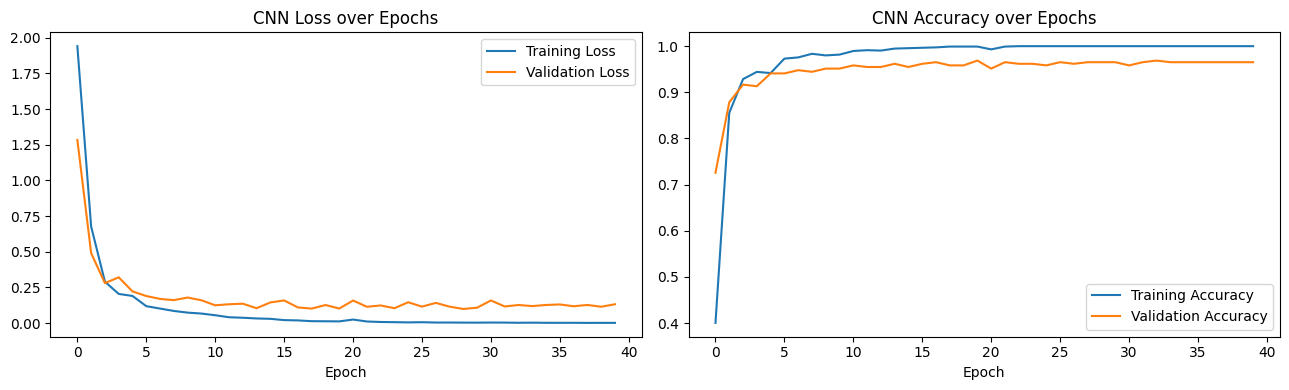

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(cnn_history.history["loss"], label="Training Loss")
axes[0].plot(cnn_history.history["val_loss"], label="Validation Loss")
axes[0].set_title("CNN Loss over Epochs")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(cnn_history.history["accuracy"], label="Training Accuracy")
axes[1].plot(cnn_history.history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("CNN Accuracy over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

### Line-by-Line Breakdown

- **`cnn_history.history`** - `.fit()` returned a `History` object, and `.history` is a dictionary inside it holding a list of numbers for each epoch - one list for training loss, one for validation loss, one for training accuracy, and one for validation accuracy.
- **`axes[0].plot(cnn_history.history["loss"], label="Training Loss")`** - Plots the training loss values, one point per epoch, and gives that line a label for the legend.
- The remaining lines repeat this same `plot()` pattern for validation loss, training accuracy, and validation accuracy, split across our two subplots exactly as we did in Week 6 Day 2.

**How to read these charts:** if training loss keeps dropping but validation loss starts climbing back up, that's overfitting - the model is starting to memorise the training images rather than learning general patterns. If both lines flatten out together at a low loss, the model has learned well and is generalising.

# Part 8 - Evaluate the CNN

In [14]:
from sklearn.metrics import confusion_matrix, classification_report

cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(X_test_cnn, y_test, verbose=0)

print("CNN Test Loss:", round(cnn_test_loss, 4))
print("CNN Test Accuracy:", round(cnn_test_accuracy, 4))

CNN Test Loss: 0.1026
CNN Test Accuracy: 0.9806


### Line-by-Line Breakdown

- **`cnn_model.evaluate(X_test_cnn, y_test, verbose=0)`** - Runs the trained model on the **test set** (images it has never learned from) and returns two numbers: the loss and the accuracy on that unseen data.
- **`cnn_test_loss, cnn_test_accuracy = ...`** - We immediately unpack those two returned values into two separate, clearly-named variables.
- **The two `print()` lines** display both numbers, rounded to 4 decimal places for readability.

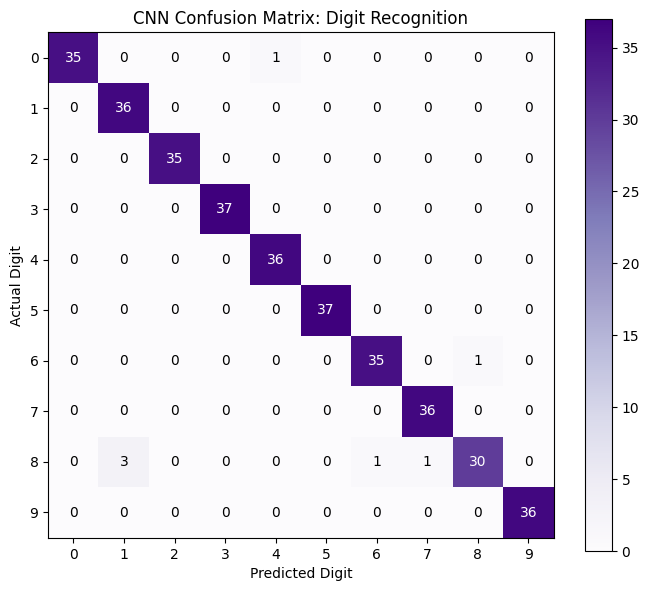

              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.92      1.00      0.96        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.97      1.00      0.99        36
           5       1.00      1.00      1.00        37
           6       0.97      0.97      0.97        36
           7       0.97      1.00      0.99        36
           8       0.97      0.86      0.91        35
           9       1.00      1.00      1.00        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



In [15]:
cnn_probabilities = cnn_model.predict(X_test_cnn, verbose=0)
cnn_predictions = np.argmax(cnn_probabilities, axis=1)

cm = confusion_matrix(y_test, cnn_predictions)

plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap="Purples")
plt.colorbar()
plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("CNN Confusion Matrix: Digit Recognition")

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                  color="white" if cm[i, j] > cm.max() / 2 else "black")

plt.tight_layout()
plt.show()

print(classification_report(y_test, cnn_predictions))

### Line-by-Line Breakdown

- **`cnn_model.predict(X_test_cnn, verbose=0)`** - Runs every test image through the trained network and returns, for each image, 10 probabilities (one per digit) - this is the `softmax` output layer at work.
- **`np.argmax(cnn_probabilities, axis=1)`** - For each image's 10 probabilities, this finds the *position* of the highest one. Since our classes are conveniently numbered `0` through `9`, that position **is** the predicted digit. `axis=1` tells NumPy to do this separately for each row (each image), rather than across the whole array at once.
- **`confusion_matrix(y_test, cnn_predictions)`** - Builds a 10x10 grid: row = the true digit, column = the predicted digit, and each cell counts how many times that combination occurred.
- **`plt.imshow(cm, cmap="Purples")`** and **`plt.colorbar()`** - Displays the confusion matrix as a colour-shaded grid, with a colour scale bar on the side so darker/lighter shading is easy to interpret.
- **`plt.xticks(range(10))` / `plt.yticks(range(10))`** - Labels each row and column with the actual digit numbers 0 through 9.
- **The nested `for i in range(10): for j in range(10):` loop with `plt.text(...)`** - Writes the actual count number directly onto each cell of the grid, choosing white or black text (`color=...`) depending on how dark that cell's background is, so the numbers stay readable everywhere.
- **`classification_report(y_test, cnn_predictions)`** - Prints precision, recall, and F1-score for each individual digit, plus overall averages - much more detailed than a single accuracy number.

# Part 9 - CNN vs ANN: A Fair, Direct Comparison

Week 6 Day 2's plain ANN (which called `Flatten()` immediately, before any `Dense` layers) reached about **97.5% test accuracy** on this same dataset, using the same train/test split approach.

Let's line that up next to today's CNN.

In [16]:
comparison_table = pd.DataFrame({
    "Model": ["ANN (Week 6 Day 2)", "CNN (Week 7 Day 1)"],
    "Preserves spatial layout?": ["No - flattens immediately", "Yes - Conv+Pool operate on the 2-D grid"],
    "Test Accuracy": ["~0.975", f"{cnn_test_accuracy:.4f}"],
})
comparison_table

,Model,Preserves spatial layout?,Test Accuracy
0,ANN (Week 6 Day 2),No - flattens immediately,~0.975
1,CNN (Week 7 Day 1),Yes - Conv+Pool operate on the 2-D grid,0.9806


### Line-by-Line Breakdown

- **`pd.DataFrame({...})`** - Builds a small table (a Pandas DataFrame) directly from a dictionary, where each key becomes a column name and each list becomes that column's values.
- **`f"{cnn_test_accuracy:.4f}"`** - An f-string (a way of inserting a variable's value directly into text). The `:.4f` part formats the number to exactly 4 decimal places, matching how we've been rounding everywhere else.
- **`comparison_table`** on its own final line - simply displays the finished table (in Jupyter, writing a variable's name as the last line of a cell automatically displays it, without needing `print()`).

### How to Read This Comparison Honestly

On this particular dataset (small, simple 8x8 digit images), both architectures perform very well, and the CNN may only match or slightly edge out the ANN - this dataset is genuinely easy for either approach. The real advantage of CNNs becomes far more dramatic on **larger, more complex, more realistic images** (full 28x28 MNIST digits, real photographs, satellite images), where spatial structure carries much more information for a flattening ANN to lose. We're seeing CNNs at their simplest here - Week 7 Day 2 builds on this with a bigger, more realistic image task.

# Mini Practical Activity

1. Change the first `Conv2D` layer from 16 filters to 8, and re-train. Does accuracy change much?
2. Remove the `MaxPooling2D` layer entirely and re-train. What happens to the model's size (check `model.summary()`) and training time?
3. Try `padding="valid"` instead of `padding="same"` on both `Conv2D` layers, and check how the shapes reported in `model.summary()` change.

### Exercise 1

Using `cv2.Sobel`, apply edge detection to 3 different digit images from the dataset (`digits.images[i]`, converted to `uint8`). Do the detected edges look like they'd help distinguish, say, a `0` from an `8`?

### Exercise 2

In Part 6's architecture diagram, identify which step corresponds to each of these code lines: `Conv2D(...)`, `MaxPooling2D(...)`, `Flatten()`, `Dense(..., activation="softmax")`. Write one sentence for each, in your own words.

### Exercise 3

Using the `comparison_table` from Part 9, write a short paragraph (3-4 sentences) explaining, in your own words, why a CNN's advantage over an ANN would likely be *larger* on full-size 28x28 MNIST images than on our small 8x8 digits.

# Lesson Summary

Today, you learned how to:

- Explain why flattening an image early loses spatial information.
- Implement 2D convolution by hand with NumPy, line by line, and understand what a feature map represents.
- Apply real Sobel edge-detection filters and connect them back to hand-written convolution.
- Explain padding (`valid` vs `same`) and stride, and how each changes output size.
- Implement max pooling and average pooling by hand, and explain why pooling is used.
- Describe a full CNN pipeline: Conv → ReLU → Pool → (repeat) → Flatten → Dense.
- Read and explain every line of a real Keras CNN (`Conv2D`, `MaxPooling2D`) on the digits dataset.
- Directly and fairly compare a CNN's performance against Week 6 Day 2's ANN on the same data.

# Functions and Concepts Learned Today

| Item | Purpose |
|---|---|
| Convolution | Slides a small filter across an image, computing a weighted sum at each position |
| Filter / Kernel | The small grid of learnable numbers used in a convolution |
| Feature Map | The output of a convolution - highlights where a pattern was detected |
| Sobel Filter | A classic hand-designed filter for detecting edges |
| Padding (`valid` / `same`) | Controls whether convolution output shrinks or stays the same size |
| Stride | How many pixels the filter moves at each step |
| Pooling (Max / Average) | Shrinks a feature map, keeping the strongest or average signal per region |
| `cv2.Sobel()` | OpenCV function that applies a Sobel edge-detection filter |
| `.reshape()` | Changes an array's shape without changing its data - used to add the "channels" dimension |
| `Conv2D` | Keras layer implementing a learnable convolution |
| `MaxPooling2D` | Keras layer implementing max pooling |
| Channels dimension | The extra dimension (`H, W, Channels`) that `Conv2D` expects, even for grayscale (1 channel) images |
| CNN pipeline | Conv → ReLU → Pool → (repeat) → Flatten → Dense → softmax |

# Key Takeaways

✅ Convolution is a weighted sum computed over a small sliding window - the same underlying arithmetic as a single neuron, applied locally.

✅ Filters used to be hand-designed (Sobel); in a CNN, they are learned automatically from data.

✅ Padding and stride together control the exact size of a convolution's output.

✅ Pooling shrinks feature maps, keeps the strongest signals, and adds tolerance to small shifts in position.

✅ A CNN preserves spatial structure for as long as possible, flattening only right before the final Dense layers.

✅ On simple, small images, an ANN and a CNN can perform similarly - the CNN's real advantage grows with image size and complexity.

# Assignment

Write a short essay (as the lesson plan requests) explaining how convolution and pooling layers work in a CNN. Your essay should:

1. Explain, in your own words, what a filter/kernel does during convolution.
2. Give an example of the kind of feature an early convolution layer might detect (e.g. edges), and what a deeper layer might detect (e.g. shapes made of edges).
3. Explain the difference between max pooling and average pooling.
4. Optionally, include your own feature map visualizations from Exercise 1 (Sobel edge detection on digit images) to support your explanation.

# Final Reflection

1. In your own words, what is a feature map?
2. Why does convolution normally shrink the image, and what fixes that?
3. What's the practical difference between `stride=1` and `stride=2`?
4. Why is max pooling more common than average pooling in most CNNs?
5. What extra dimension does `Conv2D` expect that a `Dense` layer doesn't, and why?
6. In your own words, what's the difference between a hand-designed filter (Sobel) and a CNN's learned filters?
7. Based on today's comparison table, would you expect a CNN's advantage over an ANN to grow or shrink on larger, more complex images? Why?
8. Why does a CNN only call `Flatten()` near the very end of the network, rather than at the start?

# Preview: Week 7 - Day 2

Next lesson, we scale up: training a CNN on a larger, more realistic image classification dataset, and seeing the CNN-vs-ANN gap widen as the images grow more complex. We'll also look at techniques like data augmentation, which help CNNs generalise better when training data is limited.